# Week 2: Genotyping, Population Genetics, and Privacy

**Big idea:** This week I learn that some genetic variants are common and some are rare, and that changes how easy they are to study and how much they matter for disease. Genetic data is also uniquely sensitive, because it can identify a person and their relatives even without a name.

**What I cover**
- Why genotyping data is heavily protected (people can be re-identified from it)
- How next-generation sequencing is used to read people's genotypes
- What rare (MAF under 1%), low frequency (1% to 5%), and common (over 5%) variants mean for disease

**My readings**
| Paper | What I read | Why it matters |
|---|---|---|
| Nielsen et al. 2011, *Nature Reviews Genetics* | Intro, Alignment and Assembly, Genotype and SNP Calling, Probabilistic Methods, Incorporating LD | How genotypes are read from DNA sequencing |
| Wan et al. 2022, *Nature Reviews Genetics* | All main text | Why genetic data is so sensitive |
| Lupski et al. 2011, *Cell* | All main text | Why most variants are rare, and what that means for studying disease |

**My tasks**
1. What share of SNPs are common (MAF over 5%), low frequency (1% to 5%), and rare (under 1%)?
2. How many people in the genotype files also have gene expression data?

**Weekly questions I answer on Gradescope**
1. What is the tradeoff between rare and common alleles in studying the genetics of human disease?
2. What are the risks of distributing personally identifiable genetic data?

## Biology background and vocabulary

### Allele frequency: how common is each letter?

Every SNP has exactly two alleles. The **allele frequency** is the share of all the letters in a group of people that are one allele.

Each person has 2 copies, so a group of 5 people has 10 letters at each SNP.

**Toy example.** A SNP where people have A or G. I count the A's.

```
             mom copy   dad copy   copies of A
Person 1:       A          A           2
Person 2:       A          G           1
Person 3:       G          G           0
Person 4:       G          G           0
Person 5:       G          A           1
                                     -----
                          total A:     4 out of 10 letters
```

- Share of A = 4 / 10 = **0.4**
- Share of G = 1 - 0.4 = **0.6**

The formula: **share of the counted allele = (sum of everyone's 0/1/2 counts) / (2 x number of people)**

### Minor allele frequency (MAF)

The **minor allele** is whichever allele is less common. Its share is the **MAF**, so the MAF is always between 0 and 0.5.

- In the toy above, A is the minor allele, so MAF = **0.4**
- If the counted allele had a share of 0.9, the other allele would be the minor one, so MAF = 1 - 0.9 = **0.1**

So: **MAF = the smaller of (share, 1 - share)**

### Three groups of SNPs

| Group | MAF | In 1,000 people (2,000 letters), the minor allele shows up... |
|---|---|---|
| **Rare** | under 1% | fewer than 20 times |
| **Low frequency** | 1% to 5% | 20 to 100 times |
| **Common** | over 5% | more than 100 times |

### Why most SNPs in the human genome are rare

- **New typos appear every generation.** Each baby has a few dozen brand new SNPs that neither parent had. A new SNP starts out in just one person, so it starts out rare.
- **Old typos had time to spread.** Common SNPs are mostly very old, passed down for thousands of generations.
- **The human population grew very fast recently.** More people means more new typos, and they haven't had time to spread. So there are many more rare SNPs than common ones.
- **Harmful typos get weeded out.** A SNP that causes serious disease gets passed on less often (this is called natural selection), so it stays rare. This means the SNPs with **big effects on disease tend to be rare**, and common SNPs usually have **small effects**.

### The tradeoff between rare and common SNPs

| | Common SNPs | Rare SNPs |
|---|---|---|
| How many people carry it | Many | Very few |
| Typical effect on disease | Small | Can be large |
| Easy to study? | Yes: a GWAS has lots of carriers to compare | No: need huge samples, since only a handful of people carry it |
| How they're measured | Cheap genotyping chips, plus filling in nearby SNPs using LD | Usually need sequencing, since chips and LD fill-in miss them |
| Useful for | PRS (adding up many small effects) | Explaining disease in specific families |

### How genotypes are read from DNA (sequencing)

- **Next-generation sequencing (NGS)** chops a person's DNA into millions of short pieces and reads each one. Each piece read is called a **read** (about 100 letters long).
- **Alignment:** each read is matched to the spot it came from on the **reference genome** (a standard human DNA sequence used like a map).
- **Coverage (depth):** how many reads cover one spot. 30x means 30 reads cover it.
- **SNP calling:** deciding which spots vary between people.
- **Genotype calling:** deciding each person's two letters at that spot.

**Toy example.** At one spot, a person's reads say:

```
Deep coverage (10 reads):   A A G A G G A G A G    -> 5 A, 5 G -> clearly AG
Low coverage  (2 reads):    A A                     -> AA? or AG where both reads happened to be A?
```

With few reads, it's easy to miss one of the two letters. Machines also misread about 1 letter in 100. So modern methods give each genotype a **probability** instead of a hard call, and use how common each allele is in the population and nearby SNPs (LD) to make better guesses.

### Why genetic data needs privacy protection

- **DNA is a unique ID.** Fewer than 100 independent SNPs are enough to tell any two people apart. Removing the name doesn't make it anonymous.
- **It can't be changed.** A leaked password can be reset. A leaked genome can't.
- **It reveals family.** Relatives share DNA, so one person's data says something about their parents, siblings, and children, who never agreed to share.
- **It can reveal health.** Genotypes carry information about disease risk.

Ways people have been identified from "anonymous" genetic data:

| Attack | What happens |
|---|---|
| **Re-identification** | Linking genetic data to public info (like voter lists, or surnames guessed from the Y chromosome) to find out who it is |
| **Membership inference** | Using published summary statistics (like allele frequencies from a study) to tell whether a specific person was in that study, which can reveal they have the disease studied |
| **Familial search** | Uploading DNA to a genealogy database to find relatives, then building a family tree. This is how the Golden State Killer was found in 2018 |

This is why the 1000 Genomes data I use is labeled with codes like HG00096, and why most genetic datasets require an application and a data use agreement.

### Week 2 terms

| Term | Meaning |
|---|---|
| **Allele frequency** | Share of letters in a group that are one allele |
| **MAF aka Minor Allele Frequency** | Share of the less common allele (0 to 0.5) |
| **Rare / low frequency / common** | MAF under 1% / 1% to 5% / over 5% |
| **De novo mutation** | A brand new typo in a child that neither parent had |
| **Natural selection** | Harmful variants get passed on less, so they stay rare |
| **Read** | One short piece of DNA read by a sequencing machine |
| **Reference genome** | A standard human DNA sequence used as a map |
| **Coverage (depth)** | How many reads cover one spot |
| **Genotype calling** | Deciding a person's two letters at a SNP |
| **Imputation** | Filling in unmeasured SNPs using LD with nearby measured SNPs |
| **Re-identification** | Figuring out who "anonymous" data belongs to |

## Task 1: What share of SNPs are rare, low frequency, and common?

### Step 1: Read the genotype counts for chromosome 22

The `.bed` file holds the 0/1/2 counts, but in a compressed format that `pd.read_csv` can't read. I use the `bed-reader` package. I start with chromosome 22 because it's the smallest.

In [2]:
import numpy as np
import pandas as pd
from bed_reader import open_bed

genotype_folder = "../data/raw/LDREF"

with open_bed(f"{genotype_folder}/1000G.EUR.22.bed") as bed_file:
    genotype_counts = bed_file.read()

print("Shape (people, SNPs):", genotype_counts.shape)

genotype_counts[:5, :5]

Shape (people, SNPs): (489, 17489)


array([[0., 0., 1., 1., 0.],
       [0., 0., 0., 0., 1.],
       [0., 0., 1., 1., 0.],
       [1., 1., 1., 2., 0.],
       [0., 1., 1., 1., 0.]], dtype=float32)

**What I see:** I see a table of 489 rows (people) and 17,489 columns (SNPs on chromosome 22). Each value is how many copies of the counted allele that person has at that SNP: 0, 1, or 2. This is the `.bed` file from Week 1, now readable. The rows are in the same order as the `.fam` file and the columns are in the same order as the `.bim` file.

### Step 2: Calculate the MAF of every SNP

For each SNP (each column), I add up everyone's counts and divide by the total number of letters (2 per person). Then I take the smaller of that share and 1 minus that share.

In [3]:
number_of_people = genotype_counts.shape[0]

# Share of the counted allele at each SNP
counted_allele_share = np.nanmean(genotype_counts, axis=0) / 2

# MAF = the smaller of (share, 1 - share)
minor_allele_frequency = np.minimum(counted_allele_share, 1 - counted_allele_share)

print("Number of SNPs:", len(minor_allele_frequency))
print("Smallest MAF:", minor_allele_frequency.min().round(4))
print("Largest MAF:", minor_allele_frequency.max().round(4))
minor_allele_frequency[:5].round(3)

Number of SNPs: 17489
Smallest MAF: 0.0051
Largest MAF: 0.5


array([0.26 , 0.143, 0.31 , 0.303, 0.109], dtype=float32)

**What I see:** I see one MAF for each of the 17,489 SNPs. The first five are about 0.26, 0.143, 0.31, 0.303, and 0.109. For the first SNP, that means about 26% of the letters in these 489 people are the less common allele. Every value is between 0 and 0.5, which makes sense, since the minor allele can never be more than half.

### Step 3: Put each SNP into a group

In [4]:
def maf_group(maf_values):
    return np.where(maf_values < 0.01, "rare",
           np.where(maf_values > 0.05, "common", "low_frequency"))

chr22_groups = pd.Series(maf_group(minor_allele_frequency))

chr22_summary = pd.DataFrame({
    "number_of_snps": chr22_groups.value_counts(),
    "percent": (chr22_groups.value_counts(normalize=True) * 100).round(1),
}).reindex(["common", "low_frequency", "rare"])

chr22_summary

,number_of_snps,percent
common,15633,89.4
low_frequency,1645,9.4
rare,211,1.2


**What I see:** On chromosome 22, I see about 89.4% common SNPs, 9.4% low frequency, and only 1.2% rare. That's the opposite of what I expected from the background section, where most SNPs in the human genome are rare. I check whether this holds across all chromosomes next.

### Step 4: Repeat for all 22 chromosomes

Total SNPs: 1190321


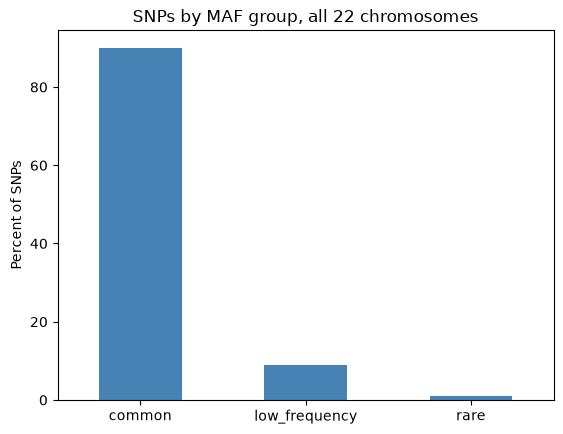

,number_of_snps,percent
common,1070777,90.0
low_frequency,106159,8.9
rare,13385,1.1


In [5]:
import matplotlib.pyplot as plt

all_mafs = []
for chromosome in range(1, 23):
    with open_bed(f"{genotype_folder}/1000G.EUR.{chromosome}.bed") as bed_file:
        counts = bed_file.read()
    share = np.nanmean(counts, axis=0) / 2
    all_mafs.append(np.minimum(share, 1 - share))

all_mafs = np.concatenate(all_mafs)
all_groups = pd.Series(maf_group(all_mafs))

all_summary = pd.DataFrame({
    "number_of_snps": all_groups.value_counts(),
    "percent": (all_groups.value_counts(normalize=True) * 100).round(1),
}).reindex(["common", "low_frequency", "rare"])

print("Total SNPs:", len(all_mafs))

all_summary["percent"].plot(kind="bar", color="steelblue")
plt.ylabel("Percent of SNPs")
plt.title("SNPs by MAF group, all 22 chromosomes")
plt.xticks(rotation=0)
plt.show()

all_summary

**What I see:** Across all 22 chromosomes there are 1,190,321 SNPs: about 90.0% common, 8.9% low frequency, and 1.1% rare. So chromosome 22 was typical.

**Why so few rare SNPs?** This dataset (LDREF) is not every SNP in these people. It was filtered to about 1.2 million mostly common SNPs (the HapMap3 set) because those are the ones that are measured well and are useful for LD. If I had the full sequencing data, rare SNPs would be the large majority. So my result describes this filtered dataset, not the human genome in general. It also means any analysis I run on this data mostly can't see rare variants.

## Task 2: How many people have both genotype and expression data?

### Step 5: Find the overlap

I only need the column names of the expression file (the people), so I read just the header with `nrows=0`.

In [ ]:
fam_column_names = ["family_id", "person_id", "dad_id", "mom_id", "sex", "trait_value"]
people_table = pd.read_csv(f"{genotype_folder}/1000G.EUR.1.fam", sep=r"\s+", header=None, names=fam_column_names)
genotyped_people = set(people_table["person_id"])

expression_path = "../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt"
expression_columns = pd.read_csv(expression_path, sep="\t", nrows=0).columns
expression_people = set(expression_columns[4:])

people_in_both = genotyped_people & expression_people

print("People with genotypes:", len(genotyped_people))
print("People with expression:", len(expression_people))
print("People in both:", len(people_in_both))

People with genotypes: 489
People with expression: 462
People in both: 344


**What I see:** I see 489 people with genotypes and 462 with expression, but only 344 in both. The genotype files have only Europeans, while Geuvadis also measured people from Africa (the Yoruba), so most of the extra expression people have no genotypes here. Some Europeans were genotyped but never had their expression measured. For anything that links SNPs to gene expression (like eQTLs next week), I can only use these 344 people.

## Readings guide

---

### 1. Nielsen et al. 2011, *Nature Reviews Genetics*: reading genotypes from sequencing data

**What it's about:** How researchers go from a sequencing machine's raw reads to each person's genotype, and why that is harder than it sounds when the data has errors or few reads.

**My notes:**
- Sequencing gives millions of short reads. They're aligned to the reference genome, then two decisions are made: which spots vary (SNP calling) and each person's two letters (genotype calling).
- Machines misread about 1% of letters, so a single read isn't trustworthy.
- Coverage: low is under 5x, medium is 5x to 20x, deep is over 20x. The 1000 Genomes pilot used about 3x for 176 people, because sequencing many people lightly finds more variants than sequencing a few people deeply.
- The old method used cutoffs (call it a heterozygote if 20% to 80% of reads show the other letter). It only works with deep coverage and misses heterozygotes at low coverage.
- The better method gives each genotype a probability. It combines what the reads say with how common each allele is in the population (a "prior"). For example, if an allele has a 1% frequency, being AA is very unlikely to begin with.
- LD helps too: SNPs near each other are inherited together, so neighbors can fill in a missing or unclear genotype. Accuracy went from about 80% (one person alone) to 87% (many people together) to 96% (adding LD).
- LD helps less for rare variants, since they're on fewer chunks of DNA.
- Genotype errors can make association studies weaker and make rare variants look more common than they are, so the uncertainty should be carried into later analysis.

---

### 2. Wan et al. 2022, *Nature Reviews Genetics*: protecting genomic data privacy

**What it's about:** The ways people can be identified from genetic data, the technical tools to prevent that, and what the laws do and don't protect, across health care, research, direct-to-consumer tests (like 23andMe), and police use.

**My notes:**
- Removing names isn't enough. Researchers re-identified people in the Personal Genome Project by matching them to voter lists, and some 1000 Genomes participants by guessing surnames from their Y chromosome.
- Fewer than 100 independent SNPs can uniquely identify a person, and hiding some SNPs doesn't help much because LD and imputation can fill them back in.
- Even summary statistics can leak: in 2008, Homer et al. showed you could tell if a specific person was part of a GWAS. That led NIH to put summary statistics behind access control (later relaxed in 2018).
- Relatives can expose you. The Golden State Killer was found in 2018 by uploading crime scene DNA to GEDmatch and finding a third cousin. A study predicted that with 1 million people in a database, 60% of searches for Europeans would find a third cousin or closer.
- Protections: access control, encryption, summary data only, adding noise (differential privacy), and fake "synthetic" datasets. Each one makes the data less useful, so there's always a tradeoff between privacy and usefulness.
- Laws have gaps. HIPAA doesn't cover de-identified data, and research on de-identified data usually doesn't need consent. GINA (2008) bans genetic discrimination in health insurance and jobs, but not in life, disability, or long-term care insurance.

---

### 3. Lupski et al. 2011, *Cell*: "clan genomics" and rare variants

**What it's about:** The authors argue that rare variants, especially recent ones that run in a family (a "clan"), may matter more for a person's disease risk than the common variants GWAS find.

**My notes:**
- The "common disease, common variant" idea led to GWAS, but GWAS findings explain only a few percent of the genetic part of common diseases.
- Each person has about 3.5 million SNPs compared to the reference, and 200,000 to 500,000 of them haven't been seen in other people's genomes. New sequencing keeps finding new private variants with every person added.
- Rare variants are so common because the human population grew very fast, and every child has new (de novo) mutations.
- Natural selection removes harmful variants before they can become common, so variants with big effects on disease should be rare.
- "Clan genomics": the variants that arose recently in my extended family may say more about my disease risk than the old common variants shared by my whole population.
- The same gene can matter for both rare and common disease. For example, carriers of one bad copy of the cystic fibrosis gene don't get cystic fibrosis but can have higher risk of pancreatitis, and at least 268 genes found by GWAS also cause rare single-gene disorders.
- Takeaway: both kinds matter. Some people's risk comes from many common variants, others from a few rare ones with big effects.

## Week 2 answers

### Task questions

**1. What share of SNPs are common, low frequency, and rare?**
Across all 22 chromosomes in the 1000 Genomes European data (1,190,321 SNPs), about 90.0% are common (MAF over 5%), 8.9% are low frequency (1% to 5%), and 1.1% are rare (under 1%). Chromosome 22 alone was similar (89.4%, 9.4%, 1.2%). This dataset was filtered to mostly common SNPs, so rare SNPs are much less represented than they are in the full human genome, where most SNPs are rare.

**2. How many people have both genotype and expression data?**
344 people. There are 489 people with genotypes and 462 with expression data, and 344 of them appear in both. These are the people I can use to connect SNPs to gene expression.

### Gradescope questions

**1. What is the tradeoff between rare and common alleles in studying the genetics of human disease?**
Common alleles are easy to study because many people carry them, so a GWAS has enough carriers to detect even a small effect, and they can be measured cheaply with genotyping chips. The downside is that each common allele usually has only a tiny effect on disease, and together the ones found so far explain only part of the genetic risk. Rare alleles can have much larger effects, since natural selection keeps harmful variants from becoming common, and they can explain disease in specific families. But because so few people carry each one, studying them takes very large samples and usually full sequencing, since genotyping chips and imputation tend to miss them. So common alleles give strong statistical power but small effects, while rare alleles can give large effects but are hard to find and confirm.

**2. What are the risks of distributing personally identifiable genetic data?**
Genetic data is a permanent ID. Fewer than 100 SNPs can tell people apart, and unlike a password, a genome can't be changed if it leaks. Removing names isn't enough, since researchers have re-identified people by linking their data to public records like voter lists, or by guessing surnames from the Y chromosome. Once someone is identified, their data can reveal health risks, which could lead to stigma or discrimination. In the US, GINA protects against discrimination in health insurance and employment, but not in life, disability, or long-term care insurance. Genetic data also exposes relatives who never agreed to share anything, since family members share DNA. For example, police found the Golden State Killer by matching crime scene DNA to a distant cousin in a public genealogy database. Even summary statistics can reveal whether a specific person was in a study, which can reveal they have the disease being studied.